
# Day 2: Customer and Restaurant Segmentation

## Objective
The objective of this analysis is to identify groups of customers and restaurants with similar ordering behavior and operational performance.

## Business Questions
1. Which customer segments are most valuable?
2. Which restaurants perform well, and which require intervention?
3. Can clustering identify unusual customers or restaurant profiles?

## Methodology
1. Load and inspect the synthetic datasets.
2. Clean the data and engineer customer and restaurant features.
3. Standardize numerical features.
4. Apply K-Means and select a suitable number of clusters.
5. Apply DBSCAN to identify dense groups and potential outliers.
6. Use PCA to visualize the clusters.
7. Profile the clusters and translate findings into business recommendations.

## Data Note
The datasets are synthetic. The analysis demonstrates machine learning techniques and should not be interpreted as actual Uber Eats business performance.


In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)

PROJECT_DIR = Path.cwd()

# If the notebook kernel starts in another directory,
# locate the project root using the expected data folder.
if not (PROJECT_DIR / "data" / "raw").exists():
    PROJECT_DIR = Path.home() / "Projects" / "uber-eats-intelligence"

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
INSIGHTS_DIR = PROJECT_DIR / "reports" / "insights"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
INSIGHTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Raw data directory:", RAW_DIR)
print("Raw data directory exists:", RAW_DIR.exists())


Project directory: /home/nineleaps/Projects/uber-eats-intelligence
Raw data directory: /home/nineleaps/Projects/uber-eats-intelligence/data/raw
Raw data directory exists: True



## Step 1: Load and Inspect the Datasets

**Why:** Before performing clustering, we must understand the structure of the data and confirm that the expected datasets are available.

**What to observe:** The number of records, columns, data types, and whether the tables contain the identifiers needed to join customer, order, restaurant, delivery, and review information.

**Next:** Load the relevant CSV files and inspect their quality before creating features.


In [2]:

customers = pd.read_csv(RAW_DIR / "customers.csv")
restaurants = pd.read_csv(RAW_DIR / "restaurants.csv")
orders = pd.read_csv(RAW_DIR / "orders.csv")
deliveries = pd.read_csv(RAW_DIR / "deliveries.csv")
drivers = pd.read_csv(RAW_DIR / "drivers.csv")
reviews = pd.read_csv(RAW_DIR / "reviews.csv")
payments = pd.read_csv(RAW_DIR / "payments.csv")

# Convert date columns to datetime
customers["signup_date"] = pd.to_datetime(
    customers["signup_date"], errors="coerce"
)
orders["order_timestamp"] = pd.to_datetime(
    orders["order_timestamp"], errors="coerce"
)

datasets = {
    "Customers": customers,
    "Restaurants": restaurants,
    "Orders": orders,
    "Deliveries": deliveries,
    "Drivers": drivers,
    "Reviews": reviews,
    "Payments": payments
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

print("\nSample orders:")
print(orders.head())

print("\nOrder data types:")
print(orders.dtypes)


Customers: 500 rows, 4 columns
Restaurants: 60 rows, 5 columns
Orders: 5000 rows, 7 columns
Deliveries: 5000 rows, 8 columns
Drivers: 100 rows, 3 columns
Reviews: 3750 rows, 6 columns
Payments: 5000 rows, 5 columns

Sample orders:
   order_id  customer_id  restaurant_id     order_timestamp  order_amount  \
0         1          145             32 2026-02-11 18:07:00        148.95   
1         2          447             32 2026-03-30 02:35:00        860.38   
2         3          374             37 2026-02-16 12:12:00        590.54   
3         4          375             53 2026-03-22 09:29:00        929.83   
4         5          139             51 2026-03-07 22:30:00        867.50   

   number_of_items order_status  
0                8    Completed  
1                3    Completed  
2                3    Cancelled  
3                1    Completed  
4                6    Completed  

Order data types:
order_id                    int64
customer_id                 int64
restaurant_id  


### Observations

The project contains seven synthetic datasets representing customers, restaurants, orders, deliveries, drivers, reviews, and payments.

The orders table contains the customer and restaurant identifiers required for aggregation. The delivery table provides delivery distance, preparation time, delivery time, weather, and traffic information.

The review table contains text and sentiment labels, but no original numeric customer rating. We must account for this when constructing customer features.

### Transition

Next, we will inspect missing values, duplicate records, invalid identifiers, and numerical ranges before building the customer and restaurant feature tables.



## Step 2: Data Quality Assessment

**Why:** Missing values, duplicate records, invalid identifiers, and unrealistic numeric values can affect clustering results.

**What to check:** Missing values, duplicate rows, primary-key uniqueness, foreign-key validity, and numeric ranges.

**Next:** Resolve any data-quality issues before constructing customer and restaurant features.


In [3]:

# 1. Check missing values and duplicate rows
for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())

# 2. Check primary-key uniqueness
primary_keys = {
    "customers": (customers, "customer_id"),
    "restaurants": (restaurants, "restaurant_id"),
    "orders": (orders, "order_id"),
    "deliveries": (deliveries, "delivery_id"),
    "drivers": (drivers, "driver_id"),
    "reviews": (reviews, "review_id"),
    "payments": (payments, "payment_id")
}

print("\nPRIMARY KEY CHECKS")
for name, (df, key) in primary_keys.items():
    print(f"{name}: unique={df[key].is_unique}, "
          f"missing={df[key].isnull().sum()}")

# 3. Check foreign-key relationships
foreign_keys = [
    ("orders.customer_id", orders["customer_id"],
     customers["customer_id"]),
    ("orders.restaurant_id", orders["restaurant_id"],
     restaurants["restaurant_id"]),
    ("deliveries.order_id", deliveries["order_id"],
     orders["order_id"]),
    ("deliveries.driver_id", deliveries["driver_id"],
     drivers["driver_id"]),
    ("reviews.order_id", reviews["order_id"],
     orders["order_id"]),
    ("payments.order_id", payments["order_id"],
     orders["order_id"])
]

print("\nFOREIGN KEY CHECKS")
for name, values, valid_values in foreign_keys:
    invalid_count = (~values.isin(valid_values)).sum()
    print(f"{name}: invalid references={invalid_count}")

# 4. Inspect numeric ranges
print("\nNUMERIC SUMMARY")
print(orders[["order_amount", "number_of_items"]].describe())
print(deliveries[
    ["delivery_distance_km", "preparation_time_minutes",
     "delivery_time_minutes"]
].describe())

# 5. Inspect order statuses
print("\nORDER STATUS COUNTS")
print(orders["order_status"].value_counts())



--- Customers ---
Missing values: 0
Duplicate rows: 0

--- Restaurants ---
Missing values: 0
Duplicate rows: 0

--- Orders ---
Missing values: 0
Duplicate rows: 0

--- Deliveries ---
Missing values: 0
Duplicate rows: 0

--- Drivers ---
Missing values: 0
Duplicate rows: 0

--- Reviews ---
Missing values: 0
Duplicate rows: 0

--- Payments ---
Missing values: 0
Duplicate rows: 0

PRIMARY KEY CHECKS
customers: unique=True, missing=0
restaurants: unique=True, missing=0
orders: unique=True, missing=0
deliveries: unique=True, missing=0
drivers: unique=True, missing=0
reviews: unique=True, missing=0
payments: unique=True, missing=0

FOREIGN KEY CHECKS
orders.customer_id: invalid references=0
orders.restaurant_id: invalid references=0
deliveries.order_id: invalid references=0
deliveries.driver_id: invalid references=0
reviews.order_id: invalid references=0
payments.order_id: invalid references=0

NUMERIC SUMMARY
       order_amount  number_of_items
count   5000.000000      5000.000000
mean    


### Data Quality Findings

- Missing values: [Record the results]
- Duplicate records: [Record the results]
- Primary-key checks: [Pass/fail]
- Foreign-key checks: [Record any invalid references]
- Numeric ranges: [Record any suspicious values]
- Order statuses: [Record the counts by status]

### Interpretation

These checks help establish whether the datasets are suitable for feature engineering. Any detected problems must be investigated and documented before modeling.

### Transition

Next, we will create analytical features for customers and restaurants. We will use completed orders for completed-transaction metrics and examine how cancelled orders affect restaurant performance.



## Step 3: Customer Feature Engineering

**Why:** Customer segmentation requires behavioral features rather than raw customer identifiers. We want to identify frequent customers, high-spending customers, and customers who order at different times.

**Features:** Total orders, average order value, total spending, ordering frequency, average rating proxy, weekend orders, and late-night orders.

**Business meaning:** These features help distinguish valuable frequent customers from occasional customers and identify different ordering habits.

**Next:** Aggregate completed orders by customer and join the results with review and customer information.


In [5]:

# Work on copies to preserve the original datasets
orders_work = orders.copy()
deliveries_work = deliveries.copy()
reviews_work = reviews.copy()

# Use completed orders for customer purchase metrics
completed_orders = orders_work[
    orders_work["order_status"] == "Completed"
].copy()

# Extract date and time features
completed_orders["order_date"] = (
    completed_orders["order_timestamp"].dt.date
)

completed_orders["order_hour"] = (
    completed_orders["order_timestamp"].dt.hour
)

completed_orders["is_weekend"] = (
    completed_orders["order_timestamp"].dt.dayofweek >= 5
).astype(int)

completed_orders["is_late_night"] = (
    (completed_orders["order_hour"] >= 22)
    | (completed_orders["order_hour"] < 5)
).astype(int)

# Aggregate purchase behavior
customer_features = completed_orders.groupby(
    "customer_id"
).agg(
    total_orders=("order_id", "count"),
    average_order_value=("order_amount", "mean"),
    total_spending=("order_amount", "sum"),
    active_order_days=("order_date", "nunique"),
    weekend_orders=("is_weekend", "sum"),
    late_night_orders=("is_late_night", "sum")
).reset_index()

# Ordering frequency: completed orders per active order day
customer_features["ordering_frequency"] = (
    customer_features["total_orders"]
    / customer_features["active_order_days"].replace(0, np.nan)
)

# Review-based proxy, not a true numeric rating
sentiment_map = {
    "Positive": 5,
    "Neutral": 3,
    "Negative": 1
}

reviews_work["sentiment_score_proxy"] = (
    reviews_work["sentiment_label"].map(sentiment_map)
)

customer_review_features = reviews_work.groupby(
    "customer_id"
).agg(
    average_rating_proxy=("sentiment_score_proxy", "mean"),
    review_count=("review_id", "count")
).reset_index()

customer_features = customer_features.merge(
    customer_review_features,
    on="customer_id",
    how="left"
)

# Retain customers with no completed orders too.
# They will be excluded from clustering if all their features are zero.
customer_features = customers[
    ["customer_id", "age", "city"]
].merge(
    customer_features,
    on="customer_id",
    how="left"
)

numeric_customer_features = [
    "total_orders",
    "average_order_value",
    "total_spending",
    "active_order_days",
    "ordering_frequency",
    "weekend_orders",
    "late_night_orders",
    "average_rating_proxy",
    "review_count"
]

customer_features[numeric_customer_features] = (
    customer_features[numeric_customer_features].fillna(0)
)

customer_features.to_csv(
    PROCESSED_DIR / "customer_features.csv", index=False
)

print("Customer feature dataset:", customer_features.shape)
print(customer_features.head())
print("\nCustomers with no completed orders:",
      (customer_features["total_orders"] == 0).sum())


Customer feature dataset: (500, 12)
   customer_id  age       city  total_orders  average_order_value  \
0            1   22  Hyderabad             8           523.516250   
1            2   55     Mumbai             6           684.243333   
2            3   49      Delhi            11           736.519091   
3            4   39      Delhi            11           734.388182   
4            5   38  Bengaluru             5           792.884000   

   total_spending  active_order_days  weekend_orders  late_night_orders  \
0         4188.13                  8               2                  3   
1         4105.46                  6               2                  3   
2         8101.71                 11               2                  5   
3         8078.27                 10               3                  2   
4         3964.42                  5               0                  0   

   ordering_frequency  average_rating_proxy  review_count  
0                 1.0              4.5

/tmp/ipykernel_45382/258127091.py:21: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  completed_orders["order_timestamp"].dt.dayofweek >= 5



## Step 4: Restaurant Feature Engineering

**Why:** Restaurant segmentation helps identify high-performing restaurants, restaurants with high cancellation rates, and restaurants that may need operational support.

**Features:** Total completed orders, completed-order revenue, average restaurant rating, average preparation time, cancellation rate, and average delivery time.

**Business meaning:** The resulting profiles can help prioritize restaurant support and identify operational issues.

**Next:** Aggregate order and delivery metrics by restaurant and save the feature-engineered dataset.


In [6]:

# Total orders and cancellations from all order statuses
restaurant_order_stats = orders_work.groupby(
    "restaurant_id"
).agg(
    total_orders=("order_id", "count"),
    cancelled_orders=(
        "order_status",
        lambda s: (s == "Cancelled").sum()
    )
).reset_index()

restaurant_order_stats["cancellation_rate"] = (
    restaurant_order_stats["cancelled_orders"]
    / restaurant_order_stats["total_orders"]
)

# Completed-order revenue
restaurant_revenue = completed_orders.groupby(
    "restaurant_id"
).agg(
    completed_orders=("order_id", "count"),
    revenue=("order_amount", "sum")
).reset_index()

# Restaurant preparation and delivery times
restaurant_deliveries = (
    completed_orders[["order_id", "restaurant_id"]]
    .merge(
        deliveries_work,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)

restaurant_delivery_stats = restaurant_deliveries.groupby(
    "restaurant_id"
).agg(
    average_preparation_time=(
        "preparation_time_minutes", "mean"
    ),
    average_delivery_time=(
        "delivery_time_minutes", "mean"
    )
).reset_index()

# Combine restaurant metrics
restaurant_features = (
    restaurants.merge(
        restaurant_order_stats,
        on="restaurant_id",
        how="left"
    )
    .merge(
        restaurant_revenue,
        on="restaurant_id",
        how="left"
    )
    .merge(
        restaurant_delivery_stats,
        on="restaurant_id",
        how="left"
    )
)

restaurant_numeric_features = [
    "total_orders",
    "cancelled_orders",
    "cancellation_rate",
    "completed_orders",
    "revenue",
    "average_preparation_time",
    "average_delivery_time"
]

restaurant_features[restaurant_numeric_features] = (
    restaurant_features[restaurant_numeric_features].fillna(0)
)

restaurant_features.to_csv(
    PROCESSED_DIR / "restaurant_features.csv", index=False
)

print("Restaurant feature dataset:", restaurant_features.shape)
print(restaurant_features.head())


Restaurant feature dataset: (60, 12)
   restaurant_id restaurant_name category       city  restaurant_rating  \
0              1    Restaurant_1  Italian  Bengaluru                2.5   
1              2    Restaurant_2  Chinese  Bengaluru                2.5   
2              3    Restaurant_3  Chinese  Bengaluru                5.0   
3              4    Restaurant_4  Chinese      Delhi                4.0   
4              5    Restaurant_5  Italian    Chennai                2.8   

   total_orders  cancelled_orders  cancellation_rate  completed_orders  \
0            75                 6           0.080000                61   
1            77                 9           0.116883                60   
2            83                 4           0.048193                73   
3            78                 3           0.038462                67   
4            87                10           0.114943                66   

    revenue  average_preparation_time  average_delivery_time  
0  4

In [7]:

print("Customer feature file exists:",
      (PROCESSED_DIR / "customer_features.csv").exists())

print("Restaurant feature file exists:",
      (PROCESSED_DIR / "restaurant_features.csv").exists())

print("\nCustomer feature summary:")
print(customer_features.describe(include="all"))

print("\nRestaurant feature summary:")
print(restaurant_features.describe(include="all"))


Customer feature file exists: True
Restaurant feature file exists: True

Customer feature summary:
        customer_id        age     city  total_orders  average_order_value  \
count    500.000000  500.00000      500    500.000000           500.000000   
unique          NaN        NaN        5           NaN                  NaN   
top             NaN        NaN  Chennai           NaN                  NaN   
freq            NaN        NaN      110           NaN                  NaN   
mean     250.500000   41.45000      NaN      8.240000           722.932870   
std      144.481833   13.70749      NaN      2.905044           146.458214   
min        1.000000   18.00000      NaN      1.000000           335.186667   
25%      125.750000   30.00000      NaN      6.000000           623.503875   
50%      250.500000   41.00000      NaN      8.000000           714.316190   
75%      375.250000   53.25000      NaN     10.000000           801.811389   
max      500.000000   65.00000      NaN    


## Step 5: Feature Scaling

**Why:** Customer features have different units and ranges. For example, total spending can be thousands, while weekend orders may be single-digit values.

K-Means and DBSCAN use distances between data points. Without scaling, large-valued features can dominate the distance calculations.

**Method:** Use StandardScaler to transform numerical features so that they have approximately zero mean and unit variance.

**Important:** Exclude customer_id from model training because it is an identifier, not a behavioral characteristic.

**Next:** Apply K-Means and compare different cluster counts using the elbow method and silhouette score.


In [8]:

customer_model_features = [
    "total_orders",
    "average_order_value",
    "total_spending",
    "ordering_frequency",
    "average_rating_proxy",
    "weekend_orders",
    "late_night_orders"
]

# Create a modeling copy
X_customer = customer_features[
    customer_model_features
].copy()

# Handle any unexpected missing or infinite values
X_customer = X_customer.replace(
    [np.inf, -np.inf], np.nan
)

X_customer = X_customer.fillna(
    X_customer.median()
)

# Scale the features
customer_scaler = StandardScaler()
X_customer_scaled = customer_scaler.fit_transform(
    X_customer
)

print("Original feature shape:", X_customer.shape)
print("Scaled feature shape:", X_customer_scaled.shape)
print("Customer ID included in model:", 
      "customer_id" in customer_model_features)


Original feature shape: (500, 7)
Scaled feature shape: (500, 7)
Customer ID included in model: False



## Step 6: Select the Number of Customer Clusters

**Why:** We need a suitable number of customer segments rather than choosing the number arbitrarily.

**Elbow method:** Compare the within-cluster sum of squared distances (inertia) for different values of K. Look for a point where the improvement starts to slow down.

**Silhouette score:** Measures how well-separated and cohesive the clusters are. Higher values generally indicate better-separated clusters.

**Next:** Compare K values from 2 to 10 and use both measures to guide our decision.


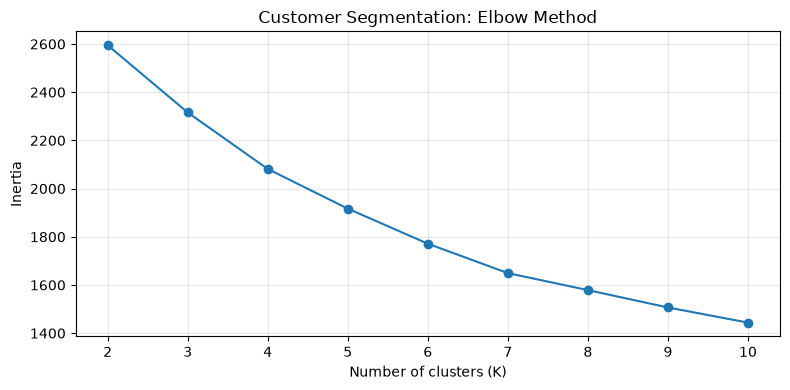

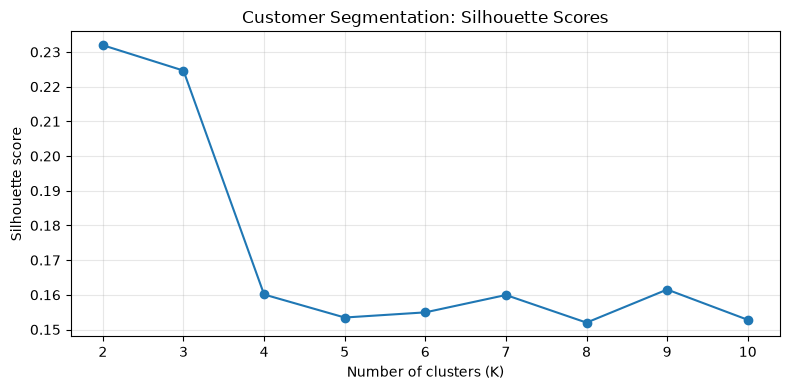

 k  inertia  silhouette_score
 2 2594.940             0.232
 3 2315.886             0.225
 4 2081.382             0.160
 5 1916.789             0.153
 6 1771.326             0.155
 7 1649.236             0.160
 8 1578.730             0.152
 9 1506.741             0.162
10 1443.805             0.153


In [9]:

inertia_values = []
silhouette_values = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_customer_scaled)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(X_customer_scaled, labels)
    )

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), inertia_values, marker="o")
plt.title("Customer Segmentation: Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "customer_elbow_plot.png",
    dpi=150
)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), silhouette_values, marker="o")
plt.title("Customer Segmentation: Silhouette Scores")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "customer_silhouette_plot.png",
    dpi=150
)
plt.show()

score_table = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertia_values,
    "silhouette_score": silhouette_values
})

print(score_table.round(3).to_string(index=False))


In [10]:

# Initial choice: three customer segments
best_k_customer = 3

customer_kmeans = KMeans(
    n_clusters=best_k_customer,
    random_state=42,
    n_init=10
)

customer_features["customer_cluster"] = (
    customer_kmeans.fit_predict(X_customer_scaled)
)

print("Customer cluster counts:")
print(
    customer_features["customer_cluster"]
    .value_counts()
    .sort_index()
)

customer_features.to_csv(
    PROCESSED_DIR / "customer_features.csv",
    index=False
)


Customer cluster counts:
customer_cluster
0    259
1    163
2     78
Name: count, dtype: int64


In [11]:

customer_profile = customer_features.groupby(
    "customer_cluster"
).agg(
    customers=("customer_id", "count"),
    avg_total_orders=("total_orders", "mean"),
    avg_order_value=("average_order_value", "mean"),
    avg_total_spending=("total_spending", "mean"),
    avg_weekend_orders=("weekend_orders", "mean"),
    avg_late_night_orders=("late_night_orders", "mean"),
    avg_sentiment_proxy=("average_rating_proxy", "mean")
).round(2)

print(customer_profile)


                  customers  avg_total_orders  avg_order_value  \
customer_cluster                                                 
0                       259              6.39           700.79   
1                       163             11.15           759.67   
2                        78              8.28           719.70   

                  avg_total_spending  avg_weekend_orders  \
customer_cluster                                           
0                            4462.77                1.77   
1                            8432.26                3.64   
2                            5925.82                2.56   

                  avg_late_night_orders  avg_sentiment_proxy  
customer_cluster                                              
0                                  1.78                 3.59  
1                                  3.64                 3.72  
2                                  2.33                 3.36  



## Step 7: PCA Visualization

**Why:** Customer clusters are formed using multiple features, which are difficult to visualize simultaneously.

**Method:** Apply Principal Component Analysis (PCA) to reduce the scaled features to two dimensions.

**Interpretation:** Each point represents a customer. Colors represent the K-Means cluster assignments. Visible separation suggests differences between groups, although PCA may not preserve every dimension of the original data.

**Next:** Save the plot and interpret the separation together with the customer cluster profiles.


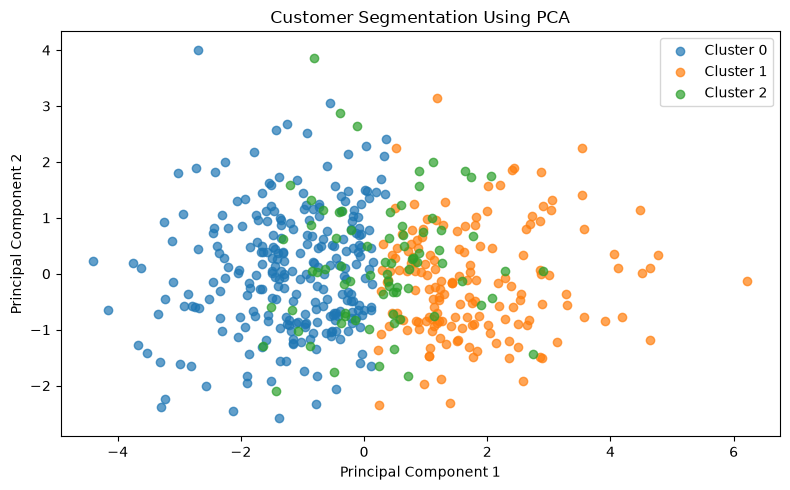

Variance explained by first two components: 0.559


In [12]:

pca_customer = PCA(n_components=2)

customer_pca = pca_customer.fit_transform(
    X_customer_scaled
)

plt.figure(figsize=(8, 5))

for cluster_id in sorted(
    customer_features["customer_cluster"].unique()
):
    mask = (
        customer_features["customer_cluster"].values
        == cluster_id
    )

    plt.scatter(
        customer_pca[mask, 0],
        customer_pca[mask, 1],
        label=f"Cluster {cluster_id}",
        alpha=0.7
    )

plt.title("Customer Segmentation Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "customer_pca_clusters.png",
    dpi=150
)
plt.show()

print(
    "Variance explained by first two components:",
    round(pca_customer.explained_variance_ratio_.sum(), 3)
)



## Step 8: Customer Segmentation Using DBSCAN

**Why:** K-Means assigns every customer to a cluster, while DBSCAN can identify customers whose feature patterns are unusual compared with dense groups.

**Method:** Apply DBSCAN to the standardized customer features.

**Evaluation:** Count the clusters and noise points. Calculate the silhouette score only when at least two non-noise clusters exist and the score is mathematically valid.

**Next:** Compare DBSCAN results with K-Means and interpret the differences.


In [13]:

# Experiment with DBSCAN parameters
dbscan_customer = DBSCAN(
    eps=1.5,
    min_samples=8
)

customer_features["dbscan_cluster"] = (
    dbscan_customer.fit_predict(X_customer_scaled)
)

print("DBSCAN cluster counts (-1 means noise):")
print(
    customer_features["dbscan_cluster"]
    .value_counts()
    .sort_index()
)

dbscan_labels = customer_features["dbscan_cluster"].to_numpy()
non_noise_mask = dbscan_labels != -1
non_noise_labels = dbscan_labels[non_noise_mask]

n_clusters = len(set(non_noise_labels))

if n_clusters >= 2:
    print(
        "DBSCAN silhouette score (excluding noise):",
        round(
            silhouette_score(
                X_customer_scaled[non_noise_mask],
                non_noise_labels
            ),
            3
        )
    )
else:
    print(
        "Silhouette score unavailable: DBSCAN found fewer than "
        "two non-noise clusters."
    )

print(
    "Noise points:",
    int((dbscan_labels == -1).sum())
)


DBSCAN cluster counts (-1 means noise):
dbscan_cluster
-1     92
 0    408
Name: count, dtype: int64
Silhouette score unavailable: DBSCAN found fewer than two non-noise clusters.
Noise points: 92



## Step 9: Restaurant Feature Scaling and K-Means

**Why:** Restaurants differ in order volume, revenue, preparation time, delivery time, and cancellation rate. Clustering these features can reveal different operational profiles.

**Method:** Exclude restaurant identifiers and non-numeric descriptive columns, handle missing or infinite values, and standardize the numerical features.

**Next:** Use the elbow method and silhouette score to select a suitable number of restaurant clusters.


In [15]:

restaurant_model_features = [
    "total_orders",
    "revenue",
    "average_preparation_time",
    "average_delivery_time",
    "cancellation_rate"
]

X_restaurant = restaurant_features[
    restaurant_model_features
].replace([np.inf, -np.inf], np.nan)

X_restaurant = X_restaurant.fillna(
    X_restaurant.median()
)

restaurant_scaler = StandardScaler()
X_restaurant_scaled = restaurant_scaler.fit_transform(
    X_restaurant
)

print("Restaurant feature matrix:", X_restaurant.shape)
print("Restaurant IDs used for training:", False)


Restaurant feature matrix: (60, 5)
Restaurant IDs used for training: False


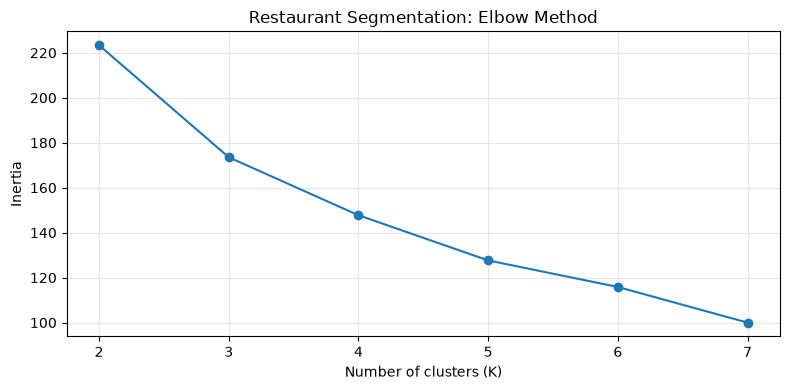

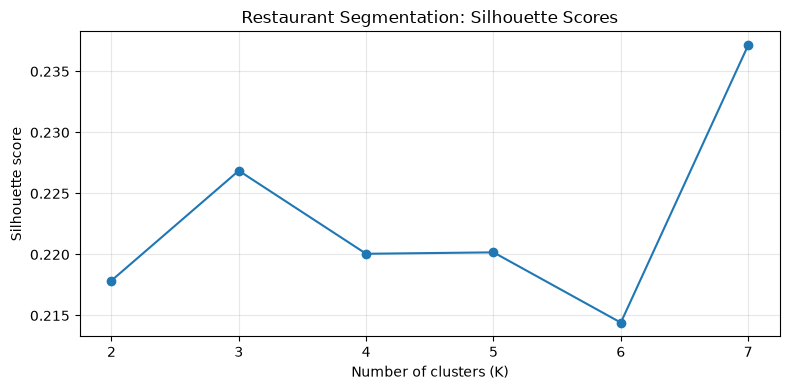

 k  inertia  silhouette_score
 2  223.379             0.218
 3  173.536             0.227
 4  147.749             0.220
 5  127.661             0.220
 6  115.839             0.214
 7   99.988             0.237


In [16]:

restaurant_k_values = range(2, 8)
restaurant_inertia = []
restaurant_silhouette = []

for k in restaurant_k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_restaurant_scaled)

    restaurant_inertia.append(model.inertia_)
    restaurant_silhouette.append(
        silhouette_score(X_restaurant_scaled, labels)
    )

plt.figure(figsize=(8, 4))
plt.plot(
    list(restaurant_k_values),
    restaurant_inertia,
    marker="o"
)
plt.title("Restaurant Segmentation: Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(restaurant_k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "restaurant_elbow_plot.png",
    dpi=150
)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(
    list(restaurant_k_values),
    restaurant_silhouette,
    marker="o"
)
plt.title("Restaurant Segmentation: Silhouette Scores")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.xticks(list(restaurant_k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "restaurant_silhouette_plot.png",
    dpi=150
)
plt.show()

print(
    pd.DataFrame({
        "k": list(restaurant_k_values),
        "inertia": restaurant_inertia,
        "silhouette_score": restaurant_silhouette
    }).round(3).to_string(index=False)
)


In [17]:

best_k_restaurant = 3

restaurant_kmeans = KMeans(
    n_clusters=best_k_restaurant,
    random_state=42,
    n_init=10
)

restaurant_features["restaurant_cluster"] = (
    restaurant_kmeans.fit_predict(X_restaurant_scaled)
)

print("Restaurant cluster counts:")
print(
    restaurant_features["restaurant_cluster"]
    .value_counts()
    .sort_index()
)


Restaurant cluster counts:
restaurant_cluster
0    25
1    17
2    18
Name: count, dtype: int64


In [18]:

restaurant_profile = restaurant_features.groupby(
    "restaurant_cluster"
).agg(
    restaurant_count=("restaurant_id", "count"),
    avg_orders=("total_orders", "mean"),
    avg_revenue=("revenue", "mean"),
    avg_preparation_time=("average_preparation_time", "mean"),
    avg_delivery_time=("average_delivery_time", "mean"),
    avg_cancellation_rate=("cancellation_rate", "mean"),
    avg_rating=("restaurant_rating", "mean")
).round(2)

print(restaurant_profile)


                    restaurant_count  avg_orders  avg_revenue  \
restaurant_cluster                                              
0                                 25       91.60     56305.16   
1                                 17       76.82     46555.92   
2                                 18       78.00     44080.53   

                    avg_preparation_time  avg_delivery_time  \
restaurant_cluster                                            
0                                  24.75              54.07   
1                                  26.27              55.63   
2                                  23.64              52.24   

                    avg_cancellation_rate  avg_rating  
restaurant_cluster                                     
0                                    0.08        3.85  
1                                    0.07        3.76  
2                                    0.09        3.81  



## Step 10: Restaurant DBSCAN and PCA

**Why:** DBSCAN can identify unusual restaurant profiles, while PCA allows us to visualize restaurant clusters in two dimensions.

**Method:** Run DBSCAN on standardized restaurant features, then apply PCA to reduce the same feature matrix to two components.

**Next:** Review cluster counts, noise points, and the PCA visualization alongside the restaurant profiles.


In [19]:

dbscan_restaurant = DBSCAN(
    eps=1.5,
    min_samples=4
)

restaurant_features["dbscan_cluster"] = (
    dbscan_restaurant.fit_predict(X_restaurant_scaled)
)

print("Restaurant DBSCAN cluster counts (-1 means noise):")
print(
    restaurant_features["dbscan_cluster"]
    .value_counts()
    .sort_index()
)

restaurant_db_labels = (
    restaurant_features["dbscan_cluster"].to_numpy()
)
restaurant_non_noise = restaurant_db_labels != -1
restaurant_non_noise_labels = (
    restaurant_db_labels[restaurant_non_noise]
)

if len(set(restaurant_non_noise_labels)) >= 2:
    print(
        "Restaurant DBSCAN silhouette score (excluding noise):",
        round(
            silhouette_score(
                X_restaurant_scaled[restaurant_non_noise],
                restaurant_non_noise_labels
            ),
            3
        )
    )
else:
    print("Restaurant DBSCAN silhouette score unavailable.")

print(
    "Restaurant noise points:",
    int((restaurant_db_labels == -1).sum())
)


Restaurant DBSCAN cluster counts (-1 means noise):
dbscan_cluster
-1    15
 0    45
Name: count, dtype: int64
Restaurant DBSCAN silhouette score unavailable.
Restaurant noise points: 15


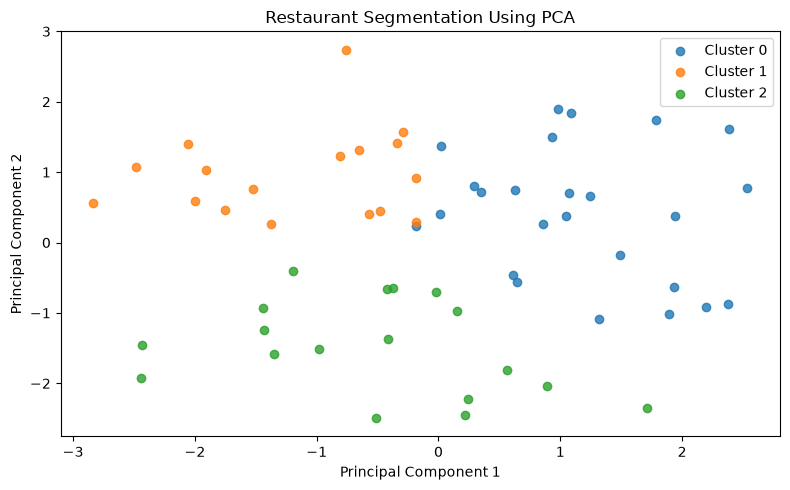

Restaurant PCA variance explained: 0.686


In [20]:

restaurant_pca_model = PCA(n_components=2)

restaurant_pca = restaurant_pca_model.fit_transform(
    X_restaurant_scaled
)

plt.figure(figsize=(8, 5))

for cluster_id in sorted(
    restaurant_features["restaurant_cluster"].unique()
):
    mask = (
        restaurant_features["restaurant_cluster"].values
        == cluster_id
    )

    plt.scatter(
        restaurant_pca[mask, 0],
        restaurant_pca[mask, 1],
        label=f"Cluster {cluster_id}",
        alpha=0.8
    )

plt.title("Restaurant Segmentation Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "restaurant_pca_clusters.png",
    dpi=150
)
plt.show()

print(
    "Restaurant PCA variance explained:",
    round(
        restaurant_pca_model.explained_variance_ratio_.sum(),
        3
    )
)



## Business Interpretation and Recommendations

### Customer Segmentation
Describe each customer cluster using its average spending, order frequency, weekend behavior, and late-night behavior.

### Restaurant Segmentation
Describe each restaurant cluster using order volume, revenue, preparation time, delivery time, rating, and cancellation rate.

### K-Means vs DBSCAN
Compare the number of groups, noise points, cluster separation, and usefulness of the resulting segments.

### PCA
Explain whether the clusters appear separated in two dimensions and report the variance explained by the first two principal components.

### Recommendations
Propose actions that follow from the actual results. For example, consider targeted loyalty offers for valuable customer segments or operational support for restaurants with elevated cancellation rates.

### Limitations
The datasets are synthetic, the review-based customer score is only a proxy, and DBSCAN results depend on the selected parameters. Cluster names and recommendations must be supported by the observed profiles.
